In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/1102965003523296.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/1500419800753647.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/193342792634899.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/208839637427980.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/324819912392369.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/3428142287286692.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/372500500837473.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/460428965043069.png
/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/mapillary_test/concrete/47

## Find manifest path and confirm the images match the path

In [2]:
import csv
from collections import Counter
from pathlib import Path
from PIL import Image

manifest_files = list(
    Path("/kaggle/input").rglob("manifest_split.csv")
)

print("Found:", manifest_files)

if len(manifest_files) != 1:
    raise ValueError(
        f"Expected one manifest, found {len(manifest_files)}. "
        "Check the paths above."
    )

MANIFEST_PATH = manifest_files[0]
DATA_ROOT = MANIFEST_PATH.parent.parent

print("Manifest:", MANIFEST_PATH)
print("Project directory:", DATA_ROOT)

Found: [PosixPath('/kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv')]
Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Project directory: /kaggle/input/datasets/nguyen700/road-types-dataset


## Check if image paths match the path in manifest

In [3]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST_PATH}")

missing_images = []

with MANIFEST_PATH.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)

    if "image_path" not in (reader.fieldnames or []):
        raise ValueError("Manifest is missing the image_path column.")

    rows = list(reader)

for row in rows:
    relative_path = row["image_path"].strip()
    image_path = DATA_ROOT / relative_path

    if not relative_path or not image_path.is_file():
        missing_images.append({
            "image_id": row.get("image_id", ""),
            "path": str(image_path),
        })

print("Manifest:", MANIFEST_PATH)
print("Total images:", len(rows))
print("Existing images:", len(rows) - len(missing_images))
print("Missing images:", len(missing_images))

for item in missing_images:
    print("Missing:", item["image_id"], item["path"])

if not rows:
    raise ValueError("Manifest is empty.")

if missing_images:
    raise FileNotFoundError("Fix missing image paths before continuing.")

Manifest: /kaggle/input/datasets/nguyen700/road-types-dataset/outputs/manifest_split.csv
Total images: 3385
Existing images: 3385
Missing images: 0


In [4]:
# 1. Đọc toàn bộ manifest và kiểm tra cấu trúc cột
with Path(MANIFEST_PATH).open(encoding="utf-8-sig", newline="") as f:
    reader = csv.DictReader(f)
    columns = reader.fieldnames
    rows = list(reader)

print("Các cột trong manifest_split.csv:", columns)
print("Tổng số dòng:", len(rows))
print("Ví dụ dòng đầu tiên:", rows[0])

# 2. Kiểm tra phân bố các tập split 
split_counts = Counter(r["split"].strip() for r in rows)
print("\n--- Số lượng ảnh theo từng split ---")
for sp, cnt in split_counts.items():
    print(f"  {sp}: {cnt} ảnh")

# Kiểm tra tên cột chứa nhãn chữ (nếu có) và class_id
label_col = next((c for c in ["class_name", "label", "surface", "category"] if c in columns), None)

print("\n--- Phân bố lớp trong từng split ---")
for sp in split_counts:
    sub = [r for r in rows if r["split"].strip() == sp]
    if label_col:
        dist = Counter((int(r["class_id"]), r[label_col].strip()) for r in sub)
    else:
        dist = Counter(int(r["class_id"]) for r in sub)
    print(f"  [{sp}]: {dict(sorted(dist.items()))}")

# 3. Kiểm tra kích thước (W, H), hệ màu (mode) và file hỏng trên TOÀN BỘ ảnh
size_counts = Counter()
mode_counts = Counter()
corrupted_files = []

for r in rows:
    img_path = Path(DATA_ROOT) / r["image_path"].strip()
    try:
        with Image.open(img_path) as img:
            size_counts[img.size] += 1   # img.size trả về (width, height)
            mode_counts[img.mode] += 1   # 'RGB', 'L', 'RGBA'...
    except Exception as e:
        corrupted_files.append((str(img_path), str(e)))

print("\n--- Thống kê kích thước ảnh (Width, Height) ---")
print(f"Tổng số loại kích thước khác nhau: {len(size_counts)}")
for sz, cnt in size_counts.most_common(10):
    print(f"  {sz}: {cnt} ảnh")

print("\n--- Thống kê hệ màu (Mode) ---")
for md, cnt in mode_counts.items():
    print(f"  {md}: {cnt} ảnh")

print(f"\n--- Số ảnh bị lỗi/không mở được: {len(corrupted_files)} ---")
if corrupted_files:
    print("  Ví dụ file lỗi:", corrupted_files[:5])

Các cột trong manifest_split.csv: ['image_id', 'image_path', 'label', 'class_id', 'split', 'longitude', 'latitude', 'captured_at', 'group_id', 'source', 'license', 'region', 'osm_way_id', 'osm_surface', 'sequence_id', 'creator', 'source_url', 'creator_url', 'osm_way_url']
Tổng số dòng: 3385
Ví dụ dòng đầu tiên: {'image_id': '1000927687276860', 'image_path': 'outputs/preprocessed/1000927687276860.png', 'label': 'concrete', 'class_id': '1', 'split': 'train', 'longitude': '13.287804599998', 'latitude': '51.5025968', 'captured_at': '1655735677353', 'group_id': 'geo_0', 'source': 'street_surface_vis', 'license': '', 'region': '', 'osm_way_id': '', 'osm_surface': '', 'sequence_id': '', 'creator': '', 'source_url': '', 'creator_url': '', 'osm_way_url': ''}

--- Số lượng ảnh theo từng split ---
  train: 2708 ảnh
  validation: 339 ảnh
  test: 338 ảnh

--- Phân bố lớp trong từng split ---
  [train]: {(0, 'unpaved'): 819, (1, 'concrete'): 788, (2, 'sett'): 1101}
  [validation]: {(0, 'unpaved'): 1

## Trích xuất đặc trưng HOG + Color Histogram

In [5]:
import cv2
import numpy as np
from skimage.feature import hog
from tqdm.auto import tqdm

IMG_SIZE = (128, 128)   
HIST_BINS = 16          

def extract_single_feature(img_path):
    img = cv2.imread(str(img_path))
    img = cv2.resize(img, IMG_SIZE)

    # 1. Trích xuất HOG trên ảnh xám
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hog_feat = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True
    )
    hog_feat = hog_feat / (np.linalg.norm(hog_feat) + 1e-7)

    # 2. Trích xuất Color Histogram trên không gian màu HSV
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist_h = cv2.calcHist([hsv], [0], None, [HIST_BINS], [0, 180]).flatten()
    hist_s = cv2.calcHist([hsv], [1], None, [HIST_BINS], [0, 256]).flatten()
    hist_v = cv2.calcHist([hsv], [2], None, [HIST_BINS], [0, 256]).flatten()
    hist_feat = np.concatenate([hist_h, hist_s, hist_v])
    hist_feat = hist_feat / (np.linalg.norm(hist_feat) + 1e-7)

    # 3. Ghép 2 vector đặc trưng
    return np.concatenate([hog_feat, hist_feat]).astype(np.float32)

def build_split_features(rows, data_root, split_name):
    sub_rows = [r for r in rows if r["split"].strip() == split_name]
    X_list, y_list = [], []
    
    for r in tqdm(sub_rows, desc=f"Extracting {split_name}"):
        img_path = Path(data_root) / r["image_path"].strip()
        feat = extract_single_feature(img_path)
        X_list.append(feat)
        y_list.append(int(r["class_id"]))
        
    return np.array(X_list), np.array(y_list, dtype=np.int64)

# Chạy trích xuất cho cả 3 tập và lưu ra /kaggle/working/
for split in ["train", "validation", "test"]:
    X, y = build_split_features(rows, DATA_ROOT, split)
    np.save(f"/kaggle/working/X_{split}.npy", X)
    np.save(f"/kaggle/working/y_{split}.npy", y)
    print(f"Saved {split}: X={X.shape}, y={y.shape}")

Extracting train:   0%|          | 0/2708 [00:00<?, ?it/s]

Saved train: X=(2708, 8148), y=(2708,)


Extracting validation:   0%|          | 0/339 [00:00<?, ?it/s]

Saved validation: X=(339, 8148), y=(339,)


Extracting test:   0%|          | 0/338 [00:00<?, ?it/s]

Saved test: X=(338, 8148), y=(338,)


## Train mô hình cơ sở (Baseline Training)

In [6]:
import time
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Nạp dữ liệu đặc trưng đã lưu từ Giai đoạn 2
X_train = np.load("/kaggle/working/X_train.npy")
y_train = np.load("/kaggle/working/y_train.npy")
X_val = np.load("/kaggle/working/X_validation.npy")
y_val = np.load("/kaggle/working/y_validation.npy")

# Kiểm tra nhanh dữ liệu hợp lệ (không chứa NaN hoặc Inf)
assert not np.isnan(X_train).any() and not np.isinf(X_train).any(), "X_train có giá trị lỗi!"
assert not np.isnan(X_val).any() and not np.isinf(X_val).any(), "X_val có giá trị lỗi!"

CLASS_NAMES = ["unpaved", "concrete", "sett"]

# 2. Khởi tạo và huấn luyện Baseline SVM
# - StandardScaler: đưa các chiều về cùng thang đo (chỉ fit trên train)
# - class_weight="balanced": tự động bù trọng số cho lớp ít mẫu hơn (unpaved, concrete)
baseline_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42)
)

t0 = time.time()
baseline_model.fit(X_train, y_train)
train_time = time.time() - t0

# 3. Đánh giá trên tập validation
t1 = time.time()
y_val_pred = baseline_model.predict(X_val)
infer_time = time.time() - t1

val_acc = accuracy_score(y_val, y_val_pred)
val_macro_f1 = f1_score(y_val, y_val_pred, average="macro")

print(f"Thời gian train: {train_time:.2f} giây")
print(f"Thời gian dự đoán ({len(X_val)} ảnh val): {infer_time:.2f} giây ({infer_time/len(X_val)*1000:.2f} ms/ảnh)")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation Macro F1: {val_macro_f1:.4f}\n")

print("--- Classification Report (Validation) ---")
print(classification_report(y_val, y_val_pred, target_names=CLASS_NAMES, digits=4))

print("--- Confusion Matrix (Validation) ---")
print(confusion_matrix(y_val, y_val_pred))

Thời gian train: 40.34 giây
Thời gian dự đoán (339 ảnh val): 6.14 giây (18.13 ms/ảnh)
Validation Accuracy: 0.7670
Validation Macro F1: 0.7630

--- Classification Report (Validation) ---
              precision    recall  f1-score   support

     unpaved     0.7094    0.8058    0.7545       103
    concrete     0.7200    0.7273    0.7236        99
        sett     0.8607    0.7664    0.8108       137

    accuracy                         0.7670       339
   macro avg     0.7634    0.7665    0.7630       339
weighted avg     0.7736    0.7670    0.7683       339

--- Confusion Matrix (Validation) ---
[[ 83  12   8]
 [ 18  72   9]
 [ 16  16 105]]


## Tinh chỉnh nhẹ & Chạy bảng đối chứng (Ablation Study)

In [7]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score

# Nạp lại dữ liệu nếu cần
X_train = np.load("/kaggle/working/X_train.npy")
y_train = np.load("/kaggle/working/y_train.npy")
X_val = np.load("/kaggle/working/X_validation.npy")
y_val = np.load("/kaggle/working/y_validation.npy")

# PHẦN A: So sánh cấu hình SVM trên cả Train & Validation (kiểm tra Underfitting / Overfitting)
configs = [
    ("Linear (C=0.1)", SVC(kernel="linear", C=0.1, class_weight="balanced", random_state=42)),
    ("Linear (C=1.0)", SVC(kernel="linear", C=1.0, class_weight="balanced", random_state=42)),
    ("RBF (C=1.0)",    SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=42)),
    ("RBF (C=3.0)",    SVC(kernel="rbf", C=3.0, gamma="scale", class_weight="balanced", random_state=42)),
    ("RBF (C=5.0)",    SVC(kernel="rbf", C=5.0, gamma="scale", class_weight="balanced", random_state=42)),
]

print("=== PHẦN A: KIỂM TRA UNDERFITTING / OVERFITTING (TRAIN vs VALIDATION) ===")
best_f1 = -1
best_name = ""
best_svm = None

for name, clf in configs:
    pipe = make_pipeline(StandardScaler(), clf)
    pipe.fit(X_train, y_train)
    
    # Đánh giá trên tập Train
    train_pred = pipe.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)
    train_f1  = f1_score(y_train, train_pred, average="macro")
    
    # Đánh giá trên tập Validation
    pred = pipe.predict(X_val)
    acc = accuracy_score(y_val, pred)
    rec = recall_score(y_val, pred, average="macro")
    f1  = f1_score(y_val, pred, average="macro")
    
    print(f"{name:<15} | Train Acc: {train_acc:.4f} (F1: {train_f1:.4f}) | Val Acc: {acc:.4f} | Val Recall: {rec:.4f} | Val F1: {f1:.4f}")
    
    if f1 > best_f1:
        best_f1 = f1
        best_name = name
        best_svm = clf

print(f"\n-> Cấu hình tốt nhất: {best_name} (Val Macro F1 = {best_f1:.4f})\n")

# PHẦN B: Bảng chứng minh hiệu quả từng đặc trưng (dùng cấu hình tốt nhất vừa tìm được)
print("=== PHẦN B: CHỨNG MINH TỪNG ĐẶC TRƯNG (ABLATION STUDY - VALIDATION) ===")
feature_sets = [
    ("Chỉ dùng Color Histogram (48 chiều)", X_train[:, -48:], X_val[:, -48:]),
    ("Chỉ dùng HOG (8100 chiều)",           X_train[:, :-48], X_val[:, :-48]),
    ("Kết hợp HOG + Color Hist (8148)",     X_train,          X_val),
]

for feat_name, X_tr_sub, X_va_sub in feature_sets:
    # Tạo bản sao tham số của best_svm để train lại từ đầu trên từng tập đặc trưng
    clf_clone = SVC(**best_svm.get_params())
    pipe = make_pipeline(StandardScaler(), clf_clone)
    pipe.fit(X_tr_sub, y_train)
    pred = pipe.predict(X_va_sub)
    
    acc = accuracy_score(y_val, pred)
    rec = recall_score(y_val, pred, average="macro")
    f1  = f1_score(y_val, pred, average="macro")
    print(f"{feat_name:<38} | Acc: {acc:.4f} | Recall: {rec:.4f} | Macro F1: {f1:.4f}")

=== PHẦN A: KIỂM TRA UNDERFITTING / OVERFITTING (TRAIN vs VALIDATION) ===
Linear (C=0.1)  | Train Acc: 1.0000 (F1: 1.0000) | Val Acc: 0.7139 | Val Recall: 0.7128 | Val F1: 0.7091
Linear (C=1.0)  | Train Acc: 1.0000 (F1: 1.0000) | Val Acc: 0.7139 | Val Recall: 0.7128 | Val F1: 0.7091
RBF (C=1.0)     | Train Acc: 0.9778 (F1: 0.9774) | Val Acc: 0.7670 | Val Recall: 0.7665 | Val F1: 0.7630
RBF (C=3.0)     | Train Acc: 1.0000 (F1: 1.0000) | Val Acc: 0.7729 | Val Recall: 0.7714 | Val F1: 0.7685
RBF (C=5.0)     | Train Acc: 1.0000 (F1: 1.0000) | Val Acc: 0.7729 | Val Recall: 0.7714 | Val F1: 0.7685

-> Cấu hình tốt nhất: RBF (C=3.0) (Val Macro F1 = 0.7685)

=== PHẦN B: CHỨNG MINH TỪNG ĐẶC TRƯNG (ABLATION STUDY - VALIDATION) ===
Chỉ dùng Color Histogram (48 chiều)    | Acc: 0.6106 | Recall: 0.6143 | Macro F1: 0.6123
Chỉ dùng HOG (8100 chiều)              | Acc: 0.7581 | Recall: 0.7559 | Macro F1: 0.7536
Kết hợp HOG + Color Hist (8148)        | Acc: 0.7729 | Recall: 0.7714 | Macro F1: 0.7685


## Đánh giá cuối cùng

=== KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST ===
Cấu hình sử dụng : RBF (C=3.0)
Test Accuracy    : 0.8609
Test Macro Recall: 0.8563
Test Macro F1    : 0.8588

--- Classification Report (Test) ---
              precision    recall  f1-score   support

     unpaved     0.8614    0.8529    0.8571       102
    concrete     0.8710    0.8182    0.8438        99
        sett     0.8542    0.8978    0.8754       137

    accuracy                         0.8609       338
   macro avg     0.8622    0.8563    0.8588       338
weighted avg     0.8613    0.8609    0.8606       338

Ví dụ đầu ra xác suất (%) mẫu test[0]: {'unpaved': 13.83, 'concrete': 24.45, 'sett': 61.72}



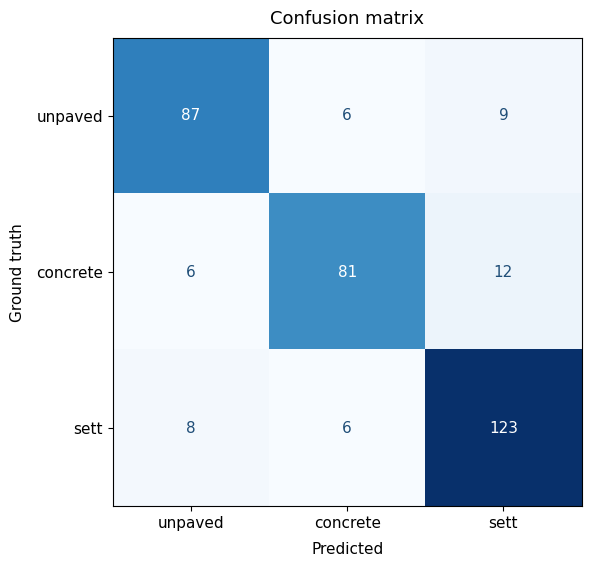

Đã lưu ảnh Confusion Matrix tại: /kaggle/working/confusion_matrix_test.png
Đã lưu thành công mô hình tại: /kaggle/working/hog_hist_svm_pipeline.joblib


In [8]:
import time
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

X_test = np.load("/kaggle/working/X_test.npy")
y_test = np.load("/kaggle/working/y_test.npy")
CLASS_NAMES = ["unpaved", "concrete", "sett"]

# Bật probability=True để mô hình xuất được xác suất (%) cho Gradio sau này
svm_params = best_svm.get_params()
svm_params["probability"] = True

final_pipeline = make_pipeline(StandardScaler(), SVC(**svm_params))
final_pipeline.fit(X_train, y_train)

y_test_pred = final_pipeline.predict(X_test)
y_test_proba = final_pipeline.predict_proba(X_test)  # Ma trận xác suất (N, 3)

test_acc = accuracy_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred, average="macro")
test_f1  = f1_score(y_test, y_test_pred, average="macro")

print("=== KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST ===")
print(f"Cấu hình sử dụng : {best_name}")
print(f"Test Accuracy    : {test_acc:.4f}")
print(f"Test Macro Recall: {test_rec:.4f}")
print(f"Test Macro F1    : {test_f1:.4f}\n")

print("--- Classification Report (Test) ---")
print(classification_report(y_test, y_test_pred, target_names=CLASS_NAMES, digits=4))

# Kiểm tra thử đầu ra % trên mẫu test đầu tiên để đảm bảo sẵn sàng cho Gradio
sample_probs = {CLASS_NAMES[i]: round(float(y_test_proba[0][i]) * 100, 2) for i in range(len(CLASS_NAMES))}
print(f"Ví dụ đầu ra xác suất (%) mẫu test[0]: {sample_probs}\n")

# --- VẼ CONFUSION MATRIX ---
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)

ax.set_title("Confusion matrix", fontsize=13, pad=10)
tick_marks = np.arange(len(CLASS_NAMES))
ax.set_xticks(tick_marks)
ax.set_xticklabels(CLASS_NAMES, fontsize=11)
ax.set_yticks(tick_marks)
ax.set_yticklabels(CLASS_NAMES, fontsize=11)

ax.set_xlabel("Predicted", fontsize=11, labelpad=8)
ax.set_ylabel("Ground truth", fontsize=11, labelpad=8)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, format(cm[i, j], "d"),
            ha="center", va="center",
            fontsize=11,
            color="white" if cm[i, j] > thresh else "#1f4e78"
        )

plt.tight_layout()
cm_fig_path = "/kaggle/working/confusion_matrix_test.png"
plt.savefig(cm_fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Đã lưu ảnh Confusion Matrix tại: {cm_fig_path}")

# Lưu toàn bộ Pipeline (gồm StandardScaler + SVC đã bật probability=True)
model_path = "/kaggle/working/hog_hist_svm_pipeline.joblib"
joblib.dump(final_pipeline, model_path)
print(f"Đã lưu thành công mô hình tại: {model_path}")

=== PHÂN TÍCH LỖI TRÊN TẬP TEST: 47/338 ẢNH DỰ ĐOÁN SAI ===


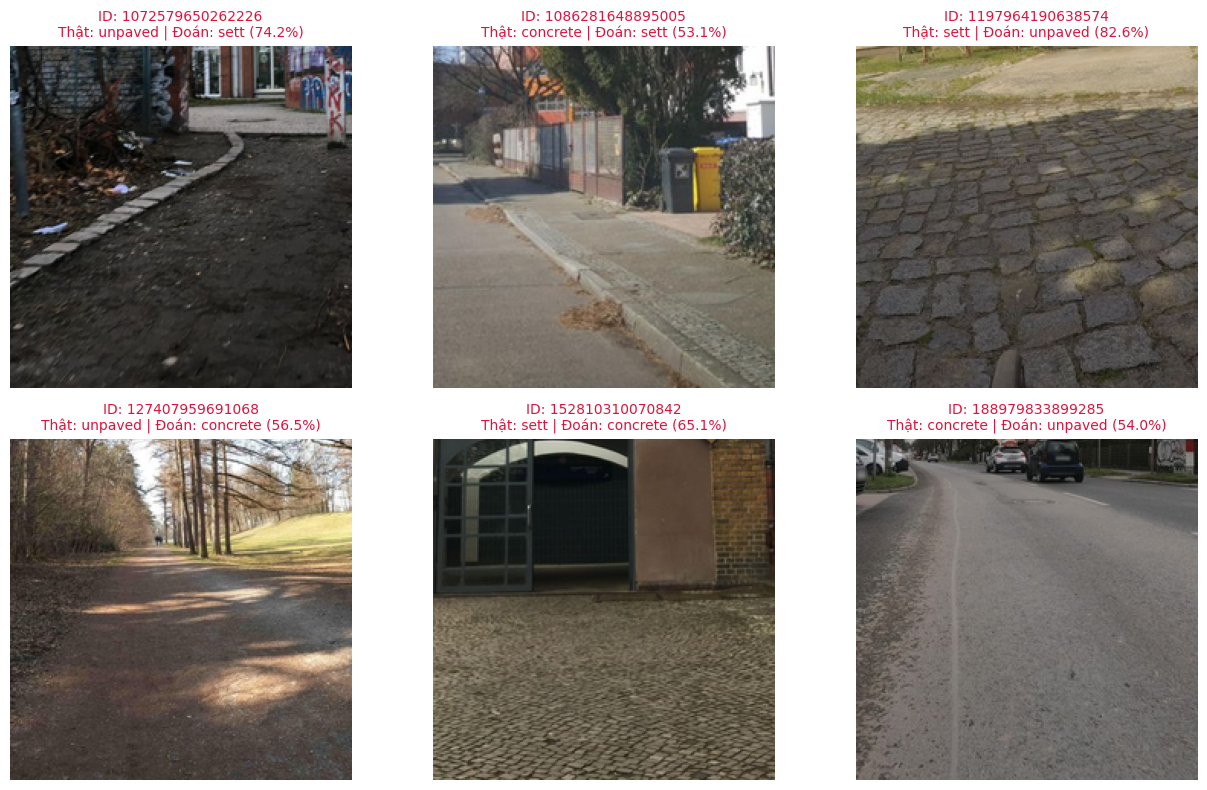

Đã lưu ảnh phân tích lỗi tại: /kaggle/working/error_analysis_test.png


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

test_rows = [r for r in rows if r["split"].strip() == "test"]
mis_indices = np.where(y_test_pred != y_test)[0]
print(f"=== PHÂN TÍCH LỖI TRÊN TẬP TEST: {len(mis_indices)}/{len(y_test)} ẢNH DỰ ĐOÁN SAI ===")

# Ưu tiên chọn 6 ảnh đại diện cho các cặp nhầm lẫn khác nhau (Thật -> Đoán)
selected = []
seen_pairs = set()
for idx in mis_indices:
    pair = (int(y_test[idx]), int(y_test_pred[idx]))
    if pair not in seen_pairs:
        selected.append(idx)
        seen_pairs.add(pair)
    if len(selected) == 6:
        break

for idx in mis_indices:
    if len(selected) == 6:
        break
    if idx not in selected:
        selected.append(idx)

# Vẽ lưới 2x3 các ảnh đoán sai kèm nhãn thật, nhãn đoán và độ tự tin (%)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(selected):
        idx = selected[i]
        r = test_rows[idx]
        img_path = Path(DATA_ROOT) / r["image_path"].strip()
        img_rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

        true_name = CLASS_NAMES[y_test[idx]]
        pred_idx = int(y_test_pred[idx])
        pred_name = CLASS_NAMES[pred_idx]
        conf = y_test_proba[idx][pred_idx] * 100

        ax.imshow(img_rgb)
        ax.set_title(
            f"ID: {r['image_id']}\nThật: {true_name} | Đoán: {pred_name} ({conf:.1f}%)",
            fontsize=10,
            color="crimson"
        )
    ax.axis("off")

plt.tight_layout()
save_fig_path = "/kaggle/working/error_analysis_test.png"
plt.savefig(save_fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Đã lưu ảnh phân tích lỗi tại: {save_fig_path}")